In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [54]:
df = pd.read_csv("../dataset/fake_job_postings.csv")

In [55]:
df.head()

,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,in_balanced_dataset
0,Marketing Intern,"US, NY, New York",Marketing,NaN,"<h3>We're Food52, and we've created a groundbr...","<p>Food52, a fast-growing, James Beard Award-w...",<ul>\r\n<li>Experience with content management...,NaN,f,t,f,Other,Internship,NaN,NaN,Marketing,f,f
1,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"<h3>90 Seconds, the worlds Cloud Video Product...",<p>Organised - Focused - Vibrant - Awesome!<br...,<p><b>What we expect from you:</b></p>\r\n<p>Y...,<h3><b>What you will get from us</b></h3>\r\n<...,f,t,f,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,f,f
2,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,<h3></h3>\r\n<p>Valor Services provides Workfo...,"<p>Our client, located in Houston, is actively...",<ul>\r\n<li>Implement pre-commissioning and co...,NaN,f,t,f,NaN,NaN,NaN,NaN,NaN,f,f
3,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,<p>Our passion for improving quality of life t...,<p><b>THE COMPANY: ESRI – Environmental System...,<ul>\r\n<li>\r\n<b>EDUCATION: </b>Bachelor’s o...,<p>Our culture is anything but corporate—we ha...,f,t,f,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,f,f
4,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,<p>SpotSource Solutions LLC is a Global Human ...,<p><b>JOB TITLE:</b> Itemization Review Manage...,<p><b>QUALIFICATIONS:</b></p>\r\n<ul>\r\n<li>R...,<p>Full Benefits Offered</p>,f,t,t,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,f,f


In [56]:
df.shape

(17880, 18)

In [57]:
df.isnull().sum()

title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                0
requirements            2689
benefits                7196
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
in_balanced_dataset        0
dtype: int64

In [58]:
missing = pd.DataFrame({
    "Column": df.columns,
    "Missing Values": df.isnull().sum().values,
    "Missing %": (df.isnull().sum().values / len(df) * 100)
})

missing.sort_values("Missing %", ascending=False)

,Column,Missing Values,Missing %
3,salary_range,15012,83.959732
2,department,11547,64.580537
13,required_education,8105,45.329978
7,benefits,7196,40.246085
12,required_experience,7050,39.429530
15,function,6455,36.101790
14,industry,4903,27.421700
11,employment_type,3471,19.412752
4,company_profile,3308,18.501119
6,requirements,2689,15.039150


In [59]:
df.duplicated().sum()

np.int64(235)

In [60]:
df = df.drop_duplicates()

In [61]:
df["fraudulent"].value_counts()

fraudulent
f    16787
t      858
Name: count, dtype: int64

In [62]:
df["fraudulent"].value_counts(normalize=True) * 100

fraudulent
f    95.137433
t     4.862567
Name: proportion, dtype: float64

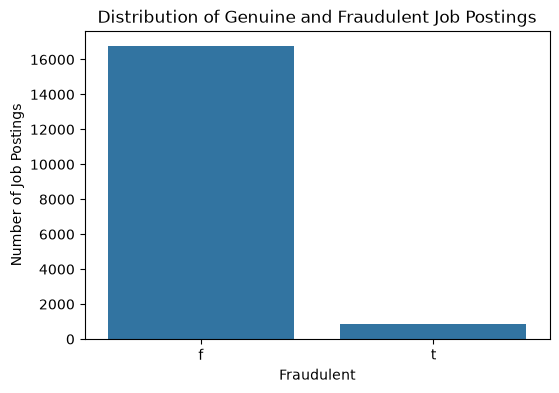

In [63]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="fraudulent")

plt.title("Distribution of Genuine and Fraudulent Job Postings")
plt.xlabel("Fraudulent")
plt.ylabel("Number of Job Postings")

plt.show()

In [64]:
df["employment_type"].value_counts()

employment_type
Full-time    11457
Contract      1517
Part-time      774
Temporary      237
Other          225
Name: count, dtype: int64

In [65]:
df["industry"].value_counts().head(10)

industry
Information Technology and Services    1712
Computer Software                      1368
Internet                               1057
Marketing and Advertising               821
Education Management                    819
Financial Services                      753
Hospital & Health Care                  486
Consumer Services                       348
Telecommunications                      329
Oil & Energy                            286
Name: count, dtype: int64

In [66]:
pd.crosstab(
    df["employment_type"],
    df["fraudulent"],
    normalize="index"
) * 100

fraudulent,f,t
employment_type,,
Contract,97.099539,2.900461
Full-time,95.740595,4.259405
Other,93.333333,6.666667
Part-time,90.568475,9.431525
Temporary,99.156118,0.843882


In [67]:
df["description_length"] = df["description"].fillna("").str.len()

In [68]:
df.groupby("fraudulent")["description_length"].describe()

,count,mean,std,min,25%,50%,75%,max
fraudulent,,,,,,,,
f,16787.0,1439.364568,1709.144901,42.0,687.0,1166.0,1779.0,55130.0
t,858.0,1438.825175,1976.996754,10.0,541.0,972.5,1774.0,29424.0


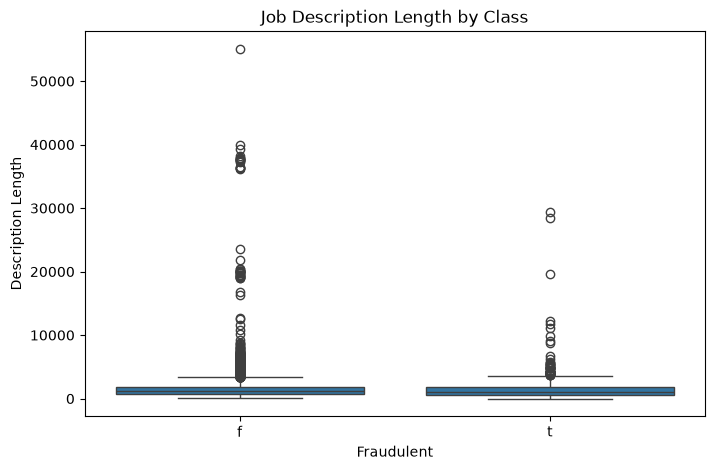

In [69]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="fraudulent",
    y="description_length"
)

plt.title("Job Description Length by Class")
plt.xlabel("Fraudulent")
plt.ylabel("Description Length")

plt.show()

In [70]:
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

In [71]:
for col in text_columns:
    df[col] = df[col].fillna("")

In [72]:
df["combined_text"] = (
    df["title"] + " " +
    df["company_profile"] + " " +
    df["description"] + " " +
    df["requirements"] + " " +
    df["benefits"]
)

In [73]:
df[["combined_text", "fraudulent"]].head()

,combined_text,fraudulent
0,"Marketing Intern <h3>We're Food52, and we've c...",f
1,Customer Service - Cloud Video Production <h3>...,f
2,Commissioning Machinery Assistant (CMA) <h3></...,f
3,Account Executive - Washington DC <p>Our passi...,f
4,Bill Review Manager <p>SpotSource Solutions LL...,f


In [74]:
df.to_csv("../dataset/job_postings_exploration.csv", index=False)

In [75]:
print(df.columns.tolist())

['title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent', 'in_balanced_dataset', 'description_length', 'combined_text']


In [76]:
employment_analysis = pd.crosstab(
    df["employment_type"].fillna("Unknown"),
    df["fraudulent"],
    normalize="index"
) * 100

print(employment_analysis)

fraudulent               f         t
employment_type                     
Contract         97.099539  2.900461
Full-time        95.740595  4.259405
Other            93.333333  6.666667
Part-time        90.568475  9.431525
Temporary        99.156118  0.843882
Unknown          93.129549  6.870451


In [77]:
df["industry"].fillna("Unknown").value_counts().head(10)

industry
Unknown                                4849
Information Technology and Services    1712
Computer Software                      1368
Internet                               1057
Marketing and Advertising               821
Education Management                    819
Financial Services                      753
Hospital & Health Care                  486
Consumer Services                       348
Telecommunications                      329
Name: count, dtype: int64

In [78]:
df["employment_type"].fillna("Unknown").value_counts()

employment_type
Full-time    11457
Unknown       3435
Contract      1517
Part-time      774
Temporary      237
Other          225
Name: count, dtype: int64

In [79]:
df["location"].fillna("Unknown").value_counts().head(10)


location
GB, LND, London          718
US, NY, New York         645
US, CA, San Francisco    469
GR, I, Athens            463
Unknown                  343
US, ,                    339
US, TX, Houston          265
US, DC, Washington       250
US, IL, Chicago          250
DE, BE, Berlin           221
Name: count, dtype: int64

In [80]:
industry_analysis = pd.crosstab(
    df["industry"].fillna("Unknown"),
    df["fraudulent"],
    normalize="index"
) * 100

print(industry_analysis.head(15))

fraudulent                                f          t
industry                                              
Accounting                        64.150943  35.849057
Airlines/Aviation                 98.412698   1.587302
Alternative Dispute Resolution   100.000000   0.000000
Animation                         60.000000  40.000000
Apparel & Fashion                 97.894737   2.105263
Architecture & Planning          100.000000   0.000000
Automotive                        95.726496   4.273504
Aviation & Aerospace             100.000000   0.000000
Banking                           96.385542   3.614458
Biotechnology                     89.473684  10.526316
Broadcast Media                   98.000000   2.000000
Building Materials                98.684211   1.315789
Business Supplies and Equipment   83.333333  16.666667
Capital Markets                  100.000000   0.000000
Chemicals                        100.000000   0.000000


In [81]:
df["salary_range"].fillna("Not Specified").value_counts().head(20)

salary_range
Not Specified    14813
0-0                141
40000-50000         66
30000-40000         54
45000-67000         36
25000-30000         36
30000-50000         32
80000-100000        30
35000-45000         30
70000-90000         29
50000-70000         28
55000-75000         28
50000-80000         28
60000-80000         28
30000-35000         27
40000-60000         27
40000-45000         27
25000-35000         26
50000-60000         24
45000-50000         22
Name: count, dtype: int64

In [82]:
df["has_salary"] = df["salary_range"].notna() & (df["salary_range"].str.strip() != "")

In [83]:
pd.crosstab(
    df["has_salary"],
    df["fraudulent"],
    normalize="index"
) * 100

fraudulent,f,t
has_salary,,
False,95.706474,4.293526
True,92.161017,7.838983


In [84]:
print(df.isnull().sum())

title                      0
location                 343
department             11362
salary_range           14813
company_profile            0
description                0
requirements               0
benefits                   0
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3435
required_experience     6976
required_education      8028
industry                4849
function                6378
fraudulent                 0
in_balanced_dataset        0
description_length         0
combined_text              0
has_salary                 0
dtype: int64


In [85]:
print(df["fraudulent"].value_counts())

fraudulent
f    16787
t      858
Name: count, dtype: int64
